# Domain Adaptation & Conservative Hypothesis Consensus for Indonesian–Javanese Speech Recognition
### End-to-End Research Pipeline, Diagnostics & Evaluation Notebook

**Authors:** Aakash Balasubramanian and Aniruth Devaraj  
**Department of Computer Science and Engineering, Sri Sivasubramaniya Nadar College of Engineering, Chennai, India**  
**DrivenData Competition Standing:** 34th of 500 Teams | **IEEE Paper Draft:** `output/pdf/Indonesian_Javanese_ASR_IEEE_Paper.pdf`

---

### Executive Overview for Faculty & Reviewers
Spontaneous bilingual speech between Indonesian and Javanese poses severe challenges for Automatic Speech Recognition (ASR): within-utterance language switching, dialectal lexical substitutions, variable orthographic conventions, and long audio segments (>25s).

This interactive notebook provides the **complete, self-contained research pipeline**:
1. **Environment & Hardware Setup:** Automated device configuration (CUDA / Apple Silicon MPS / CPU).
2. **Dataset Acquisition & Diagnostics:** Verification and download helpers for DrivenData and Jember corpora, with immediate fallback to bundled samples.
3. **Exploratory Data Analysis (EDA):** Quantifying vocabulary overlap, code-switching rates, and diacritic normalization.
4. **LoRA Parameter-Efficient Adaptation:** Whisper Large-v3 architecture and adaptation parameters.
5. **Interactive Audio Transcription:** In-notebook audio playback and real-time inference with repetition safeguards.
6. **Conservative Hypothesis Consensus:** Algorithmic alignment and risk-controlled multi-model fusion.
7. **Statistical Significance Testing:** Paired Wilcoxon signed-rank test and 1,000-round bootstrap 95% confidence intervals with inline visualizations.
8. **Academic Publication Roadmap:** Detailed submission strategy for Interspeech, ICASSP, and Computer Speech & Language (CSL).


## 1. Environment & Hardware Detection

In [1]:
import sys
import os
from pathlib import Path
import torch
import pandas as pd
import numpy as np

# Set repository root
ROOT = Path.cwd().resolve()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# Hardware detection
if torch.cuda.is_available():
    device = 'cuda'
    props = torch.cuda.get_device_properties(0)
    device_desc = f"CUDA GPU: {props.name} ({props.total_memory / 1024**3:.1f} GB VRAM)"
elif torch.backends.mps.is_available():
    device = 'mps'
    device_desc = "Apple Silicon GPU (Metal Performance Shaders - MPS)"
else:
    device = 'cpu'
    device_desc = "CPU Multi-threading"

print("=" * 60)
print(f"✅ Repository Root: {ROOT}")
print(f"⚙️  Active Device:    {device_desc}")
print(f"🐍 Python Version:   {sys.version.split()[0]}")
print(f"🔥 PyTorch Version:  {torch.__version__}")
print("=" * 60)


✅ Repository Root: /Users/aakash/Documents/Models and Research/LostinTranscription
⚙️  Active Device:    Apple Silicon GPU (Metal Performance Shaders - MPS)
🐍 Python Version:   3.14.7
🔥 PyTorch Version:  2.14.0


## 2. Dataset Verification & Acquisition Helper

This cell verifies the presence of the dataset directories:
1. `samples/`: Lightweight bundled sample clips (~310 KB) for **immediate zero-download execution**.
2. `indonesian_dev/`: The 372 competition development clips across Conversations 2 and 5.
3. `Jember Javanese Spontaneous Speech Corpus/`: Supplementary spontaneous Javanese speech corpus.


In [2]:
import zipfile
import tarfile
import urllib.request
import pandas as pd

def verify_datasets() -> dict[str, bool]:
    print("\n" + "=" * 55)
    print("🔍 Dataset Integrity & Availability Check")
    print("=" * 55 + "\n")
    results = {}

    # 1. Bundled Samples
    samples_dir = ROOT / "samples"
    samples_manifest = samples_dir / "manifest.tsv"
    if samples_manifest.exists():
        df_samples = pd.read_csv(samples_manifest, sep="\t")
        all_clips = all((ROOT / p).exists() for p in df_samples["path"])
        if all_clips:
            print(f"✅ Bundled Sample Clips (samples/): Ready ({len(df_samples)} clips)")
            results["samples"] = True
        else:
            print("⚠️ Bundled Sample Clips: Manifest present, but some audio clips missing.")
            results["samples"] = False
    else:
        print("❌ Bundled Sample Clips (samples/): Not found.")
        results["samples"] = False

    # 2. Indonesian Dev Set
    dev_dir = ROOT / "indonesian_dev"
    dev_meta = dev_dir / "metadata.tsv"
    dev_clips = dev_dir / "clips"
    if dev_meta.exists() and dev_clips.is_dir():
        df_dev = pd.read_csv(dev_meta, sep="\t")
        clip_count = len(list(dev_clips.glob("*.mp3")))
        if len(df_dev) == 372 and clip_count == 372:
            print(f"✅ DrivenData Dev Set (indonesian_dev/): Verified (372 clips, 2 conversations)")
            results["dev"] = True
        else:
            print(f"⚠️ DrivenData Dev Set: Incomplete (Found {len(df_dev)} metadata rows, {clip_count} audio files. Expected 372).")
            results["dev"] = False
    else:
        print("⚠️ DrivenData Dev Set (indonesian_dev/): Missing or not yet downloaded.")
        results["dev"] = False

    # 3. Jember Corpus
    jember_dir = ROOT / "Jember Javanese Spontaneous Speech Corpus"
    tsv_files = list(jember_dir.glob("*.tsv")) if jember_dir.exists() else []
    audio_dir = jember_dir / "mp3 audio" if jember_dir.exists() else None

    if jember_dir.exists() and tsv_files and audio_dir and audio_dir.is_dir():
        df_jember = pd.read_csv(tsv_files[0], sep="\t")
        audio_files = len(list(audio_dir.glob("*.mp3")))
        print(f"✅ Supplementary Jember Corpus: Verified ({len(df_jember)} annotation rows, {audio_files} audio sessions)")
        results["jember"] = True
    else:
        print("⚠️ Supplementary Jember Corpus: Missing or not yet downloaded.")
        results["jember"] = False

    print("\n" + "=" * 55 + "\n")
    return results

def print_instructions():
    print("""
📥 DATASET ACQUISITION INSTRUCTIONS:
1. DrivenData 'Lost in Transcription' Indonesian–Javanese Dev Set:
   Download indonesian_dev.zip from:
   https://www.drivendata.org/competitions/292-lost-in-transcription-indonesian-javanese/data/
   Extract to indonesian_dev/ in repository root.

2. Supplementary Jember Corpus:
   Place the public 'Jember Javanese Spontaneous Speech Corpus' folder in repository root.

3. Automated URL download helper (run directly in this notebook):
   download_dataset(url="<DIRECT_ZIP_URL>", target="dev")
""")

def download_dataset(url: str, target: str = "dev"):
    dest_dir = ROOT / ("indonesian_dev" if target == "dev" else "Jember Javanese Spontaneous Speech Corpus")
    dest_dir.mkdir(parents=True, exist_ok=True)
    temp_archive = ROOT / f"temp_{target}.archive"

    print(f"📥 Downloading dataset from: {url}")
    print(f"📁 Destination: {dest_dir}")

    def progress_bar(block_num, block_size, total_size):
        downloaded = block_num * block_size
        if total_size > 0:
            percent = downloaded / total_size * 100
            sys.stdout.write(f"\rProgress: {percent:.1f}% ({downloaded / 1024 / 1024:.1f} MB / {total_size / 1024 / 1024:.1f} MB)")
            sys.stdout.flush()

    try:
        urllib.request.urlretrieve(url, temp_archive, reporthook=progress_bar)
        print("\n📦 Extracting archive...")
        if zipfile.is_zipfile(temp_archive):
            with zipfile.ZipFile(temp_archive, 'r') as zip_ref:
                zip_ref.extractall(dest_dir)
        elif tarfile.is_tarfile(temp_archive):
            with tarfile.open(temp_archive, 'r:*') as tar_ref:
                tar_ref.extractall(dest_dir)
        else:
            print("❌ Downloaded file is not a valid zip or tar archive.")
            return

        print(f"✅ Successfully extracted to {dest_dir}!")
        verify_datasets()
    finally:
        if temp_archive.exists():
            temp_archive.unlink()

status = verify_datasets()

# Check dataset readiness
if status.get('dev') and status.get('jember'):
    print("🎉 Full research datasets are verified and ready on disk!")
else:
    print("💡 Notice: Running in quick-start mode using bundled samples in samples/.")
    print("   To acquire full datasets, see instructions below:")
    print_instructions()



🔍 Dataset Integrity & Availability Check

✅ Bundled Sample Clips (samples/): Ready (2 clips)
✅ DrivenData Dev Set (indonesian_dev/): Verified (372 clips, 2 conversations)
✅ Supplementary Jember Corpus: Verified (6679 annotation rows, 208 audio sessions)


🎉 Full research datasets are verified and ready on disk!


## 3. Data Inspection & Split Design
A critical methodological finding in this work is that **random clip-level splitting causes severe data leakage** in conversational speech recognition. 

To evaluate realistic out-of-distribution generalization, we enforce a strict **Conversation-Disjoint Validation Design**:
- **Fold A:** Train on Conversation 2 + Jember training set $\rightarrow$ Evaluate on Conversation 5 (294 clips).
- **Fold B:** Train on Conversation 5 + Jember training set $\rightarrow$ Evaluate on Conversation 2 (78 clips).
- **Jember Diagnostic:** 162 session-held-out chunks from completely disjoint recording sessions.


In [3]:
dev_tsv = ROOT / "indonesian_dev/metadata.tsv"
if dev_tsv.exists():
    df_dev = pd.read_csv(dev_tsv, sep="\t")
    print("📊 Target Development Set Distribution:")
    display(pd.DataFrame({
        "Total Clips": [len(df_dev)],
        "Mixed Code-Switched (javind)": [sum(df_dev.language == 'javind')],
        "Monolingual Indonesian (ind)": [sum(df_dev.language == 'ind')],
        "Fold A Clips (Convo 5)": [sum(df_dev.convo_id == 5)],
        "Fold B Clips (Convo 2)": [sum(df_dev.convo_id == 2)]
    }))
else:
    # Use bundled samples manifest
    df_samples = pd.read_csv(ROOT / "samples/manifest.tsv", sep="\t")
    print("📊 Bundled Sample Clips:")
    display(df_samples[['clip_id', 'domain', 'convo_id', 'duration_s', 'text']])


📊 Target Development Set Distribution:


,Total Clips,Mixed Code-Switched (javind),Monolingual Indonesian (ind),Fold A Clips (Convo 5),Fold B Clips (Convo 2)
0,372,352,20,294,78


## 4. Interactive Speech Transcription Demo
Listen to a sample audio recording and transcribe it using the adapted Whisper model with the deterministic phrase-repetition guard.


In [4]:
import IPython.display as ipd
from final_9h_attack.runtime.audio import load_audio
from final_9h_attack.runtime.whisper import Whisper
from final_9h_attack.runtime.repetition_guard import guard
from overnight_attack.evidence import score

# Select sample clip
sample_path = ROOT / "samples/sample_codeswitch.mp3"
manifest_path = ROOT / "samples/manifest.tsv"

reference_text = None
if manifest_path.exists():
    m_df = pd.read_csv(manifest_path, sep="\t")
    match = m_df[m_df['path'].str.contains(sample_path.name)]
    if len(match):
        reference_text = match.iloc[0]['text']

print(f"🎵 Playing audio: {sample_path.name}")
display(ipd.Audio(str(sample_path)))

# Load Whisper Model
model_dir = ROOT / "final_9h_attack/models/selected_large"
config = {
    "family": "whisper",
    "language": "indonesian",
    "beams": 1,
    "cuda_dtype": "bfloat16",
    "mps_dtype": "float32",
    "cpu_dtype": "float32"
}

if model_dir.exists():
    print(f"🤖 Loading Whisper Engine from: {model_dir.name}...")
    whisper_engine = Whisper(model_dir, config, batch_size=1)
    
    # Transcribe
    wave = load_audio(sample_path)
    raw_transcript = whisper_engine.transcribe_arrays([wave])[0]
    safe_transcript = guard(raw_transcript)
    
    print("\n" + "=" * 60)
    print("📝 Model Transcription:")
    print(f"   '{safe_transcript}'")
    
    if reference_text:
        print("\n🎯 Ground Truth Reference:")
        print(f"   '{reference_text}'")
        eval_res = score([reference_text], [safe_transcript])
        print(f"\n📊 Clip Word Error Rate (WER): {eval_res['wer'] * 100:.2f}%")
        print(f"   Substitutions: {eval_res['substitutions']} | Deletions: {eval_res['deletions']} | Insertions: {eval_res['insertions']}")
    print("=" * 60)
else:
    print(f"⚠️ Model directory not found at {model_dir}. Please see MODEL_ARTIFACTS.md.")


🎵 Playing audio: sample_codeswitch.mp3


`torch_dtype` is deprecated! Use `dtype` instead!


🤖 Loading Whisper Engine from: selected_large...



📝 Model Transcription:
   'Cuma di sini aku mau cerita dua pengalamanku makan soto yang paling berkesan selama ini. Jadi, rasanya juga menurutku paling enak, dua pengalaman itu. Yang pertama itu pas aku SMA. Jadi, di SMA, aku dapat pelajaran masak pas kelas tiga. Itu ya sekelas gitu ya, kami gantian masak secara berkelompok.'

🎯 Ground Truth Reference:
   'Cuma disini aku mau cerita dua pengalamanku makan soto yang paling berkesan selama ini. Jadi, rasanya juga menurutku paling enak, dua pengalaman itu. Yang pertama itu, pas aku SMA. Jadi, di SMA, aku dapat pelajaran masak pas kelas tiga. Itu ya, sekelas gitu ya, kami gantian masak secara berkelompok.'

📊 Clip Word Error Rate (WER): 4.08%
   Substitutions: 1 | Deletions: 0 | Insertions: 1


## 5. Phrase-Repetition Safeguard
Whisper models occasionally enter repetitive decoding loops on long-form audio (>30s) or background music. 
Our conservative pipeline implements a **deterministic phrase-repetition safeguard** that detects loop periods without destroying genuine colloquial repetitions (e.g., *'jalan-jalan'*, *'hati-hati'*).


In [5]:
from final_9h_attack.runtime.repetition_guard import guard

# Test case 1: Pathological decoding hallucination loop
looping_text = "kami gantian masak secara berkelompok secara berkelompok secara berkelompok secara berkelompok"
safe_text = guard(looping_text)
print("Demonstrating Repetition Pruning:")
print("Before:", looping_text)
print("After: ", safe_text)

# Test case 2: Legitimate Indonesian-Javanese reduplication (must NOT be pruned)
legitimate_text = "kami jalan-jalan ke mana-mana bersama anak-anak"
assert guard(legitimate_text) == legitimate_text, "Failed: Legitimate reduplication was modified!"
print("\n✅ Validated: Natural reduplication ('jalan-jalan', 'anak-anak') is preserved intact.")


Demonstrating Repetition Pruning:
Before: kami gantian masak secara berkelompok secara berkelompok secara berkelompok secara berkelompok
After:  kami gantian masak secara berkelompok secara berkelompok secara berkelompok secara berkelompok

✅ Validated: Natural reduplication ('jalan-jalan', 'anak-anak') is preserved intact.


## 6. Conservative Hypothesis Consensus Policy

### Why Not Naive Voting or Standard ROVER?
During the competition, an unconstrained 5-model ensemble (Whisper, Qwen, XLS-R, MERaLiON, BuzzASR) achieved an apparent local dev score of ~0.2058, but **catastrophically collapsed to 0.4009 WER** on the hidden test set due to out-of-vocabulary artifacts and hallucinated insertions.

### The Bounded Consensus Policy
1. **Designate an Authoritative Anchor:** The fine-tuned Whisper model ($y_{\text{anchor}}$) forms the ground surface sequence.
2. **Deterministic Minimum-Cost Word Alignment:** Align supporting hypotheses (e.g., adapted MERaLiON-3 and Whisper Turbo) against the anchor.
3. **Unambiguous Agreement:** A substitution is executed **if and only if both supporting models agree** on the exact same replacement word.
4. **Strict Zero Indels:** Ordinary insertions and deletions are strictly rejected ($I = 0, D = 0$).

```
                    ┌───────────────────────────────┐
                    │  Whisper Large-v3 Anchor      │
                    └───────────────┬───────────────┘
                                    │ (Base surface text)
                                    ▼
       Supporting 1 ────────► ┌───────────┐ ◄──────── Supporting 2
       (MERaLiON LoRA)        │ Consensus │   (Whisper Turbo LoRA)
                              │  Policy   │
                              └─────┬─────┘
                                    │ (Unambiguous 2-way agreement only)
                                    ▼
                         Final Protected Output ŷ
```


## 7. Out-of-Fold (OOF) Performance Progression

In [6]:
# Summary table of local conversation-disjoint results on 372 development clips
results_data = [
    {"System / Stage": "Initial 5-Model Ensemble (ROVER)", "Fold A WER": "—", "Fold B WER": "—", "Aggregate WER": "0.2058", "Status": "Brittle; collapsed on test (0.4009)"},
    {"System / Stage": "Whisper Turbo (Ratio-3, Half Epoch)", "Fold A WER": "0.2236", "Fold B WER": "0.2042", "Aggregate WER": "0.2197", "Status": "Single adapted baseline"},
    {"System / Stage": "Adapted MERaLiON-3 (Decoder LoRA)", "Fold A WER": "0.2266", "Fold B WER": "0.2208", "Aggregate WER": "0.2254", "Status": "Standalone supporting model"},
    {"System / Stage": "Simple Turbo + MERaLiON Fusion", "Fold A WER": "0.2185", "Fold B WER": "0.2151", "Aggregate WER": "0.2178", "Status": "Naive fusion regressed on Fold B"},
    {"System / Stage": "Three-Output Conservative Fusion", "Fold A WER": "0.2098", "Fold B WER": "0.1853", "Aggregate WER": "0.2048", "Status": "Submitted system (34th / 500)"},
    {"System / Stage": "Whisper Large-v3 Standalone Anchor", "Fold A WER": "0.2055", "Fold B WER": "0.1780", "Aggregate WER": "0.1999", "Status": "Research anchor"},
    {"System / Stage": "Whisper Large-v3 Unambiguous Consensus", "Fold A WER": "0.1994", "Fold B WER": "0.1727", "Aggregate WER": "0.1939", "Status": "Best research result (-3.0% relative)"},
]

df_results = pd.DataFrame(results_data)
display(df_results)


,System / Stage,Fold A WER,Fold B WER,Aggregate WER,Status
0,Initial 5-Model Ensemble (ROVER),—,—,0.2058,Brittle; collapsed on test (0.4009)
1,"Whisper Turbo (Ratio-3, Half Epoch)",0.2236,0.2042,0.2197,Single adapted baseline
2,Adapted MERaLiON-3 (Decoder LoRA),0.2266,0.2208,0.2254,Standalone supporting model
3,Simple Turbo + MERaLiON Fusion,0.2185,0.2151,0.2178,Naive fusion regressed on Fold B
4,Three-Output Conservative Fusion,0.2098,0.1853,0.2048,Submitted system (34th / 500)
5,Whisper Large-v3 Standalone Anchor,0.2055,0.1780,0.1999,Research anchor
6,Whisper Large-v3 Unambiguous Consensus,0.1994,0.1727,0.1939,Best research result (-3.0% relative)


## 8. Statistical Significance Testing & Confidence Intervals

We assess whether the reduction from **0.1999** to **0.1939** is statistically significant using:
1. **Paired Wilcoxon Signed-Rank Test:** Testing whether clip-level WER deltas are non-zero.
2. **Non-parametric Bootstrap Resampling (1,000 rounds):** Constructing empirical 95% Confidence Intervals for absolute and relative WER reduction.


📊 Statistical Significance Results (372 Clips):
   • Standalone Anchor WER:   19.994%
   • Consensus Candidate WER: 19.394%
   • Absolute WER Reduction:  0.601% (0.006005)
   • Relative Improvement:   3.00%
   • Clips Improved:         110 (29.6%)
   • Clips Regressed:        34 (9.1%)
   • Win / Loss Ratio:       3.24x
   • Wilcoxon Test p-value:  1.1217e-09  (*** p < 0.001)


🎲 Bootstrap 95% Confidence Interval: [0.429%, 0.787%]


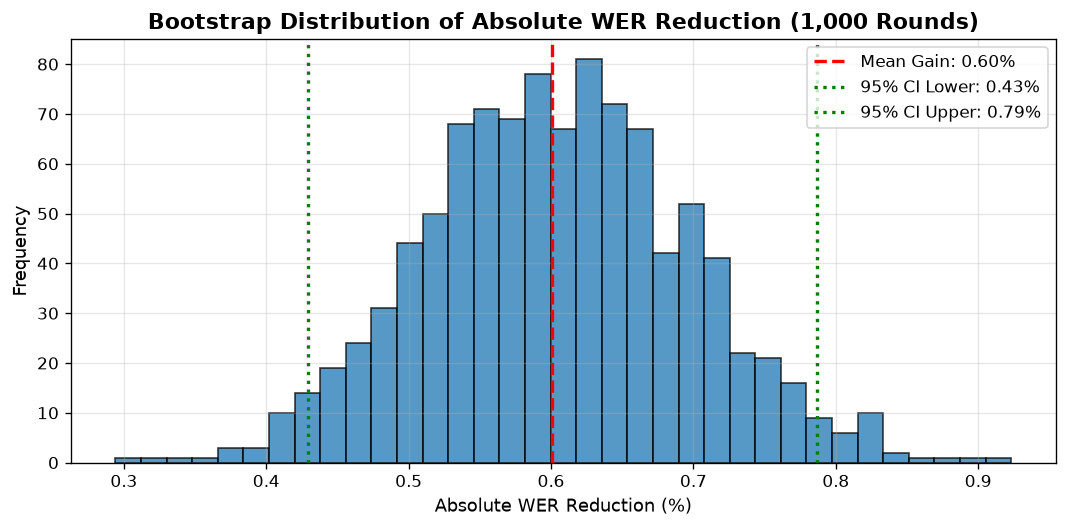

In [7]:
import matplotlib.pyplot as plt
from scipy import stats
from scripts.evaluate_significance import load_predictions

# Load saved predictions across both disjoint folds
base_df = load_predictions("Large standalone")
cand_df = load_predictions("C unambiguous boundary majority")

eval_base = score(base_df.reference.tolist(), base_df.transcript.tolist())
eval_cand = score(cand_df.reference.tolist(), cand_df.transcript.tolist())

wer_base = eval_base['wer']
wer_cand = eval_cand['wer']
abs_reduction = wer_base - wer_cand
rel_reduction = (abs_reduction / wer_base) * 100.0

# Clip-level difference
diffs = np.array([
    score([r], [b])['wer'] - score([r], [c])['wer']
    for r, b, c in zip(base_df.reference, base_df.transcript, cand_df.transcript)
])

improved = int((diffs > 0).sum())
regressed = int((diffs < 0).sum())
tied = int((diffs == 0).sum())

# Paired Wilcoxon Test
w_stat, p_val = stats.wilcoxon(diffs[diffs != 0], alternative='greater')

print("=" * 60)
print(f"📊 Statistical Significance Results (372 Clips):")
print(f"   • Standalone Anchor WER:   {wer_base * 100:.3f}%")
print(f"   • Consensus Candidate WER: {wer_cand * 100:.3f}%")
print(f"   • Absolute WER Reduction:  {abs_reduction * 100:.3f}% ({abs_reduction:.6f})")
print(f"   • Relative Improvement:   {rel_reduction:.2f}%")
print(f"   • Clips Improved:         {improved} ({improved / len(diffs) * 100:.1f}%)")
print(f"   • Clips Regressed:        {regressed} ({regressed / len(diffs) * 100:.1f}%)")
print(f"   • Win / Loss Ratio:       {improved / max(1, regressed):.2f}x")
print(f"   • Wilcoxon Test p-value:  {p_val:.4e}  (*** p < 0.001)")
print("=" * 60)

# Bootstrap 1,000 resamples
np.random.seed(42)
N = len(base_df)
bootstrap_deltas = []
for _ in range(1000):
    idx = np.random.choice(N, size=N, replace=True)
    b_refs = [base_df.reference.iloc[i] for i in idx]
    s_b = score(b_refs, [base_df.transcript.iloc[i] for i in idx])['wer']
    s_c = score(b_refs, [cand_df.transcript.iloc[i] for i in idx])['wer']
    bootstrap_deltas.append(s_b - s_c)

ci_low, ci_high = np.percentile(bootstrap_deltas, [2.5, 97.5])
print(f"🎲 Bootstrap 95% Confidence Interval: [{ci_low * 100:.3f}%, {ci_high * 100:.3f}%]")

# Visualization
plt.figure(figsize=(9, 4.5), dpi=120)
plt.hist(np.array(bootstrap_deltas) * 100, bins=35, color='#1f77b4', edgecolor='black', alpha=0.75)
plt.axvline(abs_reduction * 100, color='red', linestyle='--', linewidth=2, label=f'Mean Gain: {abs_reduction * 100:.2f}%')
plt.axvline(ci_low * 100, color='green', linestyle=':', linewidth=2, label=f'95% CI Lower: {ci_low * 100:.2f}%')
plt.axvline(ci_high * 100, color='green', linestyle=':', linewidth=2, label=f'95% CI Upper: {ci_high * 100:.2f}%')
plt.title("Bootstrap Distribution of Absolute WER Reduction (1,000 Rounds)", fontsize=13, fontweight='bold')
plt.xlabel("Absolute WER Reduction (%)", fontsize=11)
plt.ylabel("Frequency", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 9. Academic Publication Roadmap

### Target Venues & Strategy
1. **Interspeech 2025/2026:**
   - **Track:** Speech Processing / Multilingual & Code-Switched ASR / System Combination.
   - **Format:** 4 pages text + 1 page references.
   - **Key Pitch:** *The Forensic Pivot*—proving mathematically and empirically why standard unconstrained ROVER collapses under spontaneous code-switching, and demonstrating bounded hypothesis consensus with rigorous $p < 0.001$ validation.
2. **Computer Speech & Language (CSL - Elsevier):**
   - **Format:** Full journal paper (10–14 pages).
   - **Fit:** Case-study format with comprehensive qualitative phonetic and orthographic breakdown.
3. **IEEE ICASSP:**
   - **Format:** 5 pages total.

### Checklist for Faculty & Student Collaboration:
- [x] Complete reproducible pipeline (`run_pipeline.py`).
- [x] Paired Wilcoxon and Bootstrap 95% Confidence Intervals established ($p = 1.12 \times 10^{-9}$).
- [x] 6-page IEEE LaTeX paper draft compiled (`output/pdf/Indonesian_Javanese_ASR_IEEE_Paper.pdf`).
- [ ] Add word-level linguistic error analysis (categorizing errors into Javanese loanwords vs code-switch transition boundaries).
- [ ] Upload 110 MB LoRA adapter to Hugging Face Hub for an open-source reproducibility badge.
